#  Step 1: NLP Fundamentals, Text Preprocessing & RegEx


## 1.1  Theory Notes 

## **What is NLP?**

Natural Language Processing (NLP) is a branch of Artificial Intelligence (AI) that enables computers to understand, analyze, and process human language. It helps machines read text, understand its meaning, and generate useful responses. NLP combines linguistics, machine learning, and computer science to solve language-related problems.

---

## **Why do Businesses Need NLP?**

Businesses generate a large amount of text data from emails, customer reviews, chats, and social media. NLP helps analyze this data automatically, saving time and improving decision-making.

### Applications of NLP
1. Chatbots for customer support.
2. Language translation (Google Translate).
3. Sentiment analysis of customer reviews.

---

## **Challenges in NLP**

### 1. Ambiguity
A word or sentence can have multiple meanings.

**Example:** "I saw her duck."

### 2. Sarcasm
The intended meaning is opposite to the actual words.

**Example:** "Great! My phone stopped working."

### 3. Spelling Mistakes
Typing errors make text difficult to understand.

**Example:** "I luv this movi."

### 4. Hinglish / Code Mixing
Mixing multiple languages in one sentence.

**Example:** "Movie bahut mast thi."

---

## **Basic NLP Pipeline**

1. Collect Text Data
2. Text Cleaning
3. Tokenization
4. Stopword Removal
5. Stemming/Lemmatization
6. Feature Extraction
7. Train Machine Learning Model
8. Prediction

### **NLP Pipeline Flow**

Raw Text

↓

Text Cleaning

↓

Tokenization

↓

Stopword Removal

↓

Lemmatization

↓

Feature Extraction

↓

Machine Learning Model

↓

Prediction

## 1.2  Load & Explore

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_style("whitegrid")

In [7]:
# Load dataset
df = pd.read_csv("D:\\NLP\\Practical Exam\\Dataset\\spam.csv", encoding="latin-1")

# Keep only first two columns
df = df.iloc[:, :2]

# Rename columns
df.columns = ["label", "text"]

In [8]:
print("Dataset Shape:", df.shape)

Dataset Shape: (5572, 2)


- The dataset contains **5,572 SMS messages**.
- It has **2 columns**:
  - **label** (ham/spam)
  - **text** (message content)
- Each row represents one SMS message.

In [9]:
# Display First 5 Rows
df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


- The **label** column shows whether the message is **ham** or **spam**.
- The **text** column contains the actual SMS message.
- This preview helps us understand the dataset structure.

In [10]:
# Check Dataset Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   text    5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


- The dataset contains **5,572 records**.
- Both columns have **no missing values**.
- The data type of both columns is **object (string)**.

In [11]:
# Check Missing Values
df.isnull().sum()

label    0
text     0
dtype: int64

- No missing values are present in the dataset.


In [12]:
# Count Ham and Spam Messages
df["label"].value_counts()

label
ham     4825
spam     747
Name: count, dtype: int64

- The dataset contains two classes:
  - **Ham** (Normal messages)
  - **Spam** (Unwanted promotional messages)
- Ham messages are more frequent than spam messages.

C:\Users\Meet Anghan\AppData\Local\Temp\ipykernel_10972\3791743329.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="label", palette="Set2")


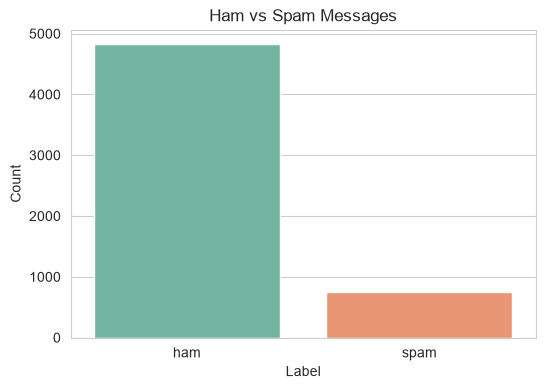

In [13]:
# Countplot
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="label", palette="Set2")

plt.title("Ham vs Spam Messages")
plt.xlabel("Label")
plt.ylabel("Count")

plt.show()

- The graph shows that **ham messages are much higher than spam messages**.
- This indicates that the dataset is **imbalanced**.

In [14]:
# Calculate Spam Percentage
spam_percentage = (df["label"] == "spam").mean() * 100

print(f"Spam Percentage: {spam_percentage:.2f}%")

Spam Percentage: 13.41%


- Approximately **13%** of the messages are spam.
- Around **87%** of the messages are ham.
- This confirms that spam messages are much fewer than ham messages.

In [15]:
# Add Message Length Column
df["msg_length"] = df["text"].apply(len)

df.head()

,label,text,msg_length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


- A new column **msg_length** has been created.
- It stores the number of characters in each SMS message.
- This feature can help distinguish spam and ham messages.

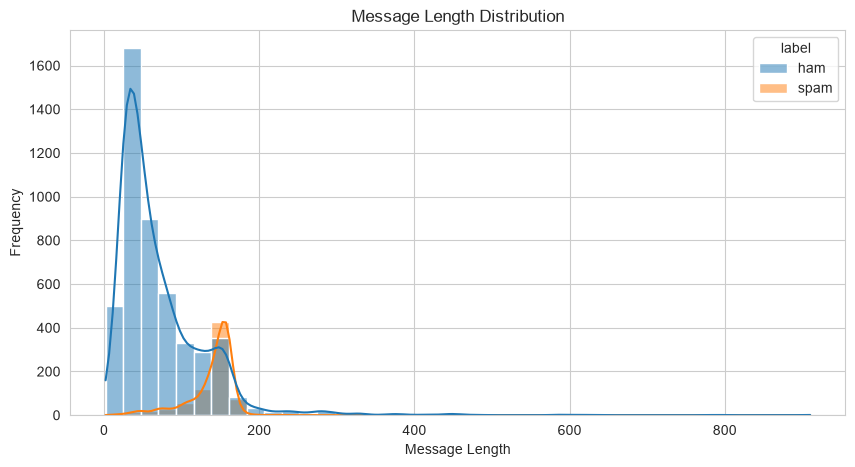

In [16]:
# Histogram of Message Length
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x="msg_length",
    hue="label",
    bins=40,
    kde=True
)

plt.title("Message Length Distribution")
plt.xlabel("Message Length")
plt.ylabel("Frequency")

plt.show()

In [17]:
df.groupby("label")["msg_length"].mean()

label
ham      71.023627
spam    138.866131
Name: msg_length, dtype: float64

- Spam messages generally have **longer text** than ham messages.
- Ham messages are usually short personal conversations.
- Spam messages often include promotional offers, links, or detailed information, making them longer.

In [18]:
# Final Dataset Preview
df.head()

,label,text,msg_length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


### Overall Interpretation

- The dataset contains **5,572 SMS messages** with **ham** and **spam** labels.
- There are **no missing values** in the dataset.
- Ham messages are more frequent than spam messages.
- Spam messages make up about **13%** of the dataset.
- Spam messages generally have **longer message lengths** than ham messages.
- The dataset is now ready for **Regular Expressions (RegEx)** and **Text Preprocessing** in the next step.

## 1.3  Regular Expressions (RegEx)


In [19]:
import re

In [20]:
# Pattern for URL
url_pattern = r'(http|www)\S+'

# Find URL messages
url_messages = df[df["text"].str.contains(url_pattern, regex=True, na=False)]

print("Total Messages with URL :", len(url_messages))
print("\nSpam Messages :", (url_messages["label"]=="spam").sum())
print("Ham Messages :", (url_messages["label"]=="ham").sum())

Total Messages with URL : 107

Spam Messages : 105
Ham Messages : 2


C:\Users\Meet Anghan\AppData\Local\Temp\ipykernel_10972\1095259499.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  url_messages = df[df["text"].str.contains(url_pattern, regex=True, na=False)]


- Regular Expression was used to identify messages containing URLs.
- Most URL-containing messages belong to the spam category.
- Spam messages often include links to websites for advertisements or scams.

In [21]:
phone_pattern = r'\d{10,}'

phone_messages = df[df["text"].str.contains(phone_pattern, regex=True, na=False)]

print("Total Messages with Phone Numbers :", len(phone_messages))

phone_messages[["label","text"]].head(3)

Total Messages with Phone Numbers : 406


,label,text
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


- Messages containing phone numbers were identified using RegEx.
- Phone numbers are commonly found in promotional and spam messages.
- Three example messages are displayed for verification.

In [22]:
currency_pattern = r'[£$]'

currency_messages = df[df["text"].str.contains(currency_pattern, regex=True, na=False)]

print("Total Messages with Currency Symbols :", len(currency_messages))

spam_percentage = (
    (currency_messages["label"]=="spam").sum()
    / len(currency_messages)
)*100

print(f"Spam Percentage : {spam_percentage:.2f}%")

Total Messages with Currency Symbols : 275
Spam Percentage : 93.45%


- Messages containing £ or $ symbols were extracted.
- Most of these messages belong to the spam category because they advertise prizes, rewards, or money offers.
- The spam percentage confirms that currency symbols are strong indicators of spam messages.

In [23]:
# Replace Numbers with "NUM"
df["text_num"] = df["text"].apply(lambda x: re.sub(r'\d+', "NUM", x))

comparison = pd.DataFrame({
    "Original": df["text"].head(3),
    "After Replacement": df["text_num"].head(3)
})

comparison

,Original,After Replacement
0,"Go until jurong point, crazy.. Available only ...","Go until jurong point, crazy.. Available only ..."
1,Ok lar... Joking wif u oni...,Ok lar... Joking wif u oni...
2,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in NUM a wkly comp to win FA Cup fi...


In [24]:
for i in range(3):
    print("Original :")
    print(df["text"].iloc[i])

    print("\nAfter :")
    print(df["text_num"].iloc[i])

    print("-"*80)

Original :
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

After :
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
--------------------------------------------------------------------------------
Original :
Ok lar... Joking wif u oni...

After :
Ok lar... Joking wif u oni...
--------------------------------------------------------------------------------
Original :
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's

After :
Free entry in NUM a wkly comp to win FA Cup final tkts NUMst May NUM. Text FA to NUM to receive entry question(std txt rate)T&C's apply NUMoverNUM's
--------------------------------------------------------------------------------


- All numeric values were replaced with the token **NUM** using `re.sub()`.
- This helps reduce unnecessary variations in numbers while preserving the sentence structure.
- Replacing numbers improves text preprocessing and helps the model focus on meaningful words instead of specific numeric values.

## 1.4  Text Preprocessing Pipeline


In [25]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [26]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to C:\Users\Meet
[nltk_data]     Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Meet
[nltk_data]     Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\Meet
[nltk_data]     Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\Meet
[nltk_data]     Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to C:\Users\Meet
[nltk_data]     Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [27]:
# Create Stopwords and Lemmatizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

In [28]:
# Create clean_text() Function
def clean_text(text):
    
    # Convert to lowercase
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r'(http|www)\S+', '', text)
    
    # Keep only letters and spaces
    text = re.sub(r'[^a-z\s]', '', text)
    
    # Tokenization
    words = word_tokenize(text)
    
    # Remove stopwords
    words = [word for word in words if word not in stop_words]
    
    # Lemmatization
    words = [lemmatizer.lemmatize(word) for word in words]
    
    # Join words
    return " ".join(words)

In [29]:
df["clean_text"] = df["text"].apply(clean_text)

In [30]:
comparison = pd.DataFrame({
    "Original Text": df["text"].head(5),
    "Cleaned Text": df["clean_text"].head(5)
})

comparison

,Original Text,Cleaned Text
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think go usf life around though


In [31]:
for i in range(5):
    print("Original Text:")
    print(df["text"].iloc[i])

    print("\nCleaned Text:")
    print(df["clean_text"].iloc[i])

    print("-"*100)

Original Text:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Cleaned Text:
go jurong point crazy available bugis n great world la e buffet cine got amore wat
----------------------------------------------------------------------------------------------------
Original Text:
Ok lar... Joking wif u oni...

Cleaned Text:
ok lar joking wif u oni
----------------------------------------------------------------------------------------------------
Original Text:
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's

Cleaned Text:
free entry wkly comp win fa cup final tkts st may text fa receive entry questionstd txt ratetcs apply over
----------------------------------------------------------------------------------------------------
Original Text:
U dun say so early hor... U c already then say...

Cleaned Text:
u dun say early

In [32]:
df.head()

,label,text,msg_length,text_num,clean_text
0,ham,"Go until jurong point, crazy.. Available only ...",111,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,29,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,Free entry in NUM a wkly comp to win FA Cup fi...,free entry wkly comp win fa cup final tkts st ...
3,ham,U dun say so early hor... U c already then say...,49,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,"Nah I don't think he goes to usf, he lives aro...",nah dont think go usf life around though


- All text messages were converted to lowercase to maintain consistency.
- URLs and special characters were removed using Regular Expressions (RegEx).
- The text was tokenized into individual words using **NLTK word_tokenize()**.
- Common English stopwords such as **is, the, and, of** were removed.
- Words were converted to their base form using **WordNet Lemmatizer**.
- Finally, the cleaned words were joined back into a single sentence and stored in a new column named **clean_text**.
- The cleaned text is now ready for feature extraction techniques like **Bag of Words (BoW), TF-IDF, and Word2Vec**.

## 1.5  Stemming vs Lemmatization


In [33]:
from nltk.stem import PorterStemmer

# Create Stemmer and Lemmatizer
porter = PorterStemmer()
lemmatizer = WordNetLemmatizer()

In [34]:
words = ["running", "flies", "better", "studies", "wolves", "cars", "was", "happily"]

In [35]:
# Apply Stemming and Lemmatization
result = pd.DataFrame({
    "Original Word": words,
    "Porter Stem": [porter.stem(word) for word in words],
    "WordNet Lemma": [lemmatizer.lemmatize(word) for word in words]
})

result

,Original Word,Porter Stem,WordNet Lemma
0,running,run,running
1,flies,fli,fly
2,better,better,better
3,studies,studi,study
4,wolves,wolv,wolf
5,cars,car,car
6,was,wa,wa
7,happily,happili,happily


## Difference Between Stemming and Lemmatization

### Stemming

Stemming is the process of removing prefixes or suffixes from a word to obtain its root form. It follows simple rule-based algorithms and does not consider the meaning or grammar of the word. As a result, it may produce incomplete or invalid words.

**Example:**
- Running → Run
- Studies → Studi
- Wolves → Wolv

---

### Lemmatization

Lemmatization converts a word into its meaningful base form (lemma) using vocabulary and grammatical rules. It considers the context and part of speech, producing valid dictionary words.

**Example:**
- Running → Run
- Studies → Study
- Wolves → Wolf

---

### Difference Between Stemming and Lemmatization

| Stemming | Lemmatization |
|----------|---------------|
| Removes prefixes/suffixes | Converts word to its dictionary form |
| Rule-based approach | Dictionary and grammar-based approach |
| Faster | Slower |
| Less accurate | More accurate |
| May produce invalid words | Produces meaningful words |

---

### Which is Slower but More Accurate?

**Lemmatization** is slower but more accurate because it uses a dictionary and grammatical rules to identify the correct base form of a word. Stemming is faster because it simply removes word endings without considering the word's meaning.

## 1.6  Word Frequency

In [36]:
from collections import Counter
from itertools import chain

In [37]:
# Separate Spam and Ham Messages
spam_text = df[df["label"] == "spam"]["clean_text"]
ham_text = df[df["label"] == "ham"]["clean_text"]

In [38]:
# Find Top 15 Words in Spam Messages
spam_words = list(chain.from_iterable(text.split() for text in spam_text))

spam_freq = Counter(spam_words)

top_spam = pd.DataFrame(
    spam_freq.most_common(15),
    columns=["Word", "Frequency"]
)

top_spam


,Word,Frequency
0,call,362
1,free,219
2,u,163
3,txt,151
4,ur,144
5,text,138
6,mobile,136
7,stop,116
8,claim,115
9,reply,103


- The table shows the **15 most frequent words** found in spam messages.
- These words are commonly used in promotional or fraudulent SMS messages.
- They can help identify spam messages effectively.

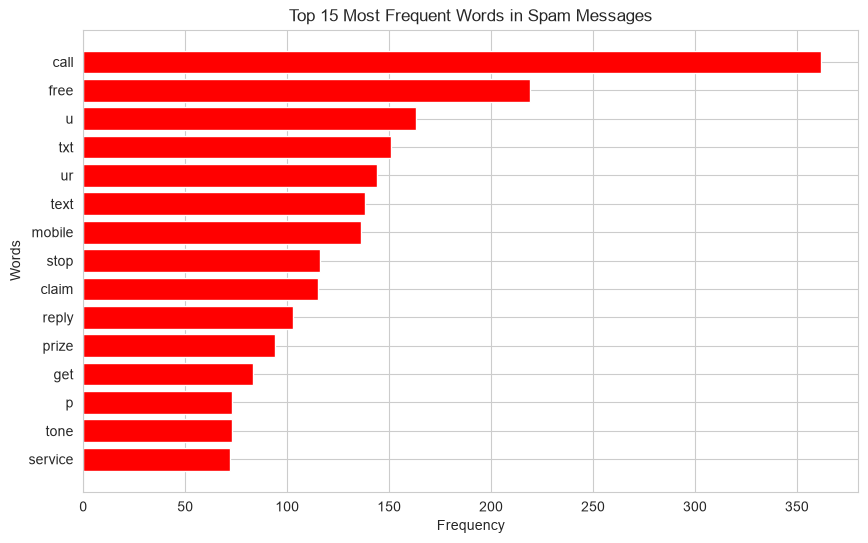

In [39]:
plt.figure(figsize=(10,6))

plt.barh(top_spam["Word"], top_spam["Frequency"], color="red")

plt.title("Top 15 Most Frequent Words in Spam Messages")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.gca().invert_yaxis()

plt.show()

- Words such as **free, call, txt, claim, prize, mobile** appear frequently in spam messages.
- These words are strong indicators of promotional or fraudulent content.

In [40]:
ham_words = list(chain.from_iterable(text.split() for text in ham_text))

ham_freq = Counter(ham_words)

top_ham = pd.DataFrame(
    ham_freq.most_common(15),
    columns=["Word", "Frequency"]
)

top_ham

,Word,Frequency
0,u,1043
1,im,461
2,get,318
3,ltgt,276
4,go,275
5,ok,272
6,dont,268
7,got,244
8,come,242
9,know,241


- The table displays the **15 most common words** in ham messages.
- These words are generally used in normal daily conversations.

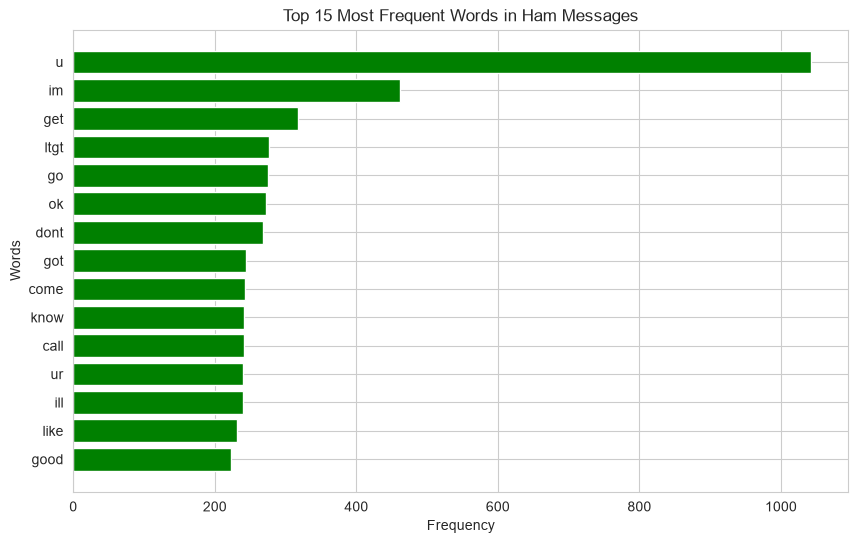

In [41]:
plt.figure(figsize=(10,6))

plt.barh(top_ham["Word"], top_ham["Frequency"], color="green")

plt.title("Top 15 Most Frequent Words in Ham Messages")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.gca().invert_yaxis()

plt.show()

- Ham messages mainly contain conversational words such as **ok, come, got, home, know**.
- These words represent regular communication rather than advertisements.

### Word Frequency Analysis

The most frequent words in **spam messages** include terms such as **free, call, txt, mobile, claim, prize, and win**. These words are commonly used in advertisements, promotional offers, and scam messages to attract users.

These words are useful for a spam classifier because they frequently appear in spam messages but rarely occur in normal conversations. Machine learning models can use these high-frequency words as important features to accurately distinguish between spam and ham messages.

# Step 2: Feature Extraction — Bag-of-Words, TF-IDF & N-Grams

## 2.1  Bag-of-Words (BoW) on the Tiny Corpus


### What is Bag-of-Words?

Bag-of-Words (BoW) is a feature extraction technique that converts text into numerical form by counting how many times each word appears in a document.

It ignores grammar, sentence structure, and word order, considering only the frequency of words. Each unique word becomes a feature, and each document is represented as a vector of word counts.

In [42]:
from sklearn.feature_extraction.text import CountVectorizer


In [43]:
# Create Tiny Corpus
documents = [
    "the movie was good",
    "the movie was bad",
    "good acting and good story",
    "not a good movie"
]

In [44]:
vectorizer = CountVectorizer()

X = vectorizer.fit_transform(documents)

In [45]:
print("Vocabulary:\n")

print(vectorizer.get_feature_names_out())

Vocabulary:

['acting' 'and' 'bad' 'good' 'movie' 'not' 'story' 'the' 'was']


In [46]:
bow_df = pd.DataFrame(
    X.toarray(),
    columns=vectorizer.get_feature_names_out(),
    index=["Doc1","Doc2","Doc3","Doc4"]
)

bow_df

,acting,and,bad,good,movie,not,story,the,was
Doc1,0,0,0,1,1,0,0,1,1
Doc2,0,0,1,0,1,0,0,1,1
Doc3,1,1,0,2,0,0,1,0,0
Doc4,0,0,0,1,1,1,0,0,0


In [47]:
print("Shape of BoW Matrix:", bow_df.shape)

Shape of BoW Matrix: (4, 9)


- Each **row** represents one document.
- Each **column** represents a unique word (feature).
- The values indicate how many times a word appears in a document.
- For example, if the value is **2**, that word appears twice in that document.
- If the value is **0**, the word does not appear in that document.

## 2.2  TF-IDF on the Tiny Corpus


### What is TF-IDF?

TF-IDF is a feature extraction technique that measures how important a word is in a document compared to the entire collection of documents (corpus).

Unlike Bag of Words, TF-IDF reduces the importance of common words and gives higher weight to unique and informative words.

In [48]:
from sklearn.feature_extraction.text import TfidfVectorizer

documents = [
    "the movie was good",
    "the movie was bad",
    "good acting and good story",
    "not a good movie"
]

In [49]:
tfidf = TfidfVectorizer()

X = tfidf.fit_transform(documents)

In [50]:
print(tfidf.get_feature_names_out())

['acting' 'and' 'bad' 'good' 'movie' 'not' 'story' 'the' 'was']


In [51]:
tfidf_df = pd.DataFrame(
    X.toarray(),
    columns=tfidf.get_feature_names_out(),
    index=["Doc1","Doc2","Doc3","Doc4"]
)

tfidf_df.round(2)

,acting,and,bad,good,movie,not,story,the,was
Doc1,0.00,0.00,0.00,0.44,0.44,0.00,0.00,0.55,0.55
Doc2,0.00,0.00,0.61,0.00,0.39,0.00,0.00,0.48,0.48
Doc3,0.46,0.46,0.00,0.59,0.00,0.00,0.46,0.00,0.00
Doc4,0.00,0.00,0.00,0.47,0.47,0.74,0.00,0.00,0.00


In [52]:
comparison = tfidf_df[["movie","acting"]].round(2)

comparison

,movie,acting
Doc1,0.44,0.00
Doc2,0.39,0.00
Doc3,0.00,0.46
Doc4,0.47,0.00


- **Movie** appears in multiple documents, so its TF-IDF score is lower.
- **Acting** appears in only one document, so it receives a higher TF-IDF score.
- TF-IDF gives more importance to unique and informative words while reducing the weight of frequently occurring words.

## 2.3  N-Grams

### What are N-Grams?

N-Grams are sequences of **N consecutive words**.

- Unigram → One word
- Bigram → Two consecutive words
- Trigram → Three consecutive words

N-Grams help preserve word order and context, improving text understanding.

In [53]:
from sklearn.feature_extraction.text import CountVectorizer

bigram = CountVectorizer(ngram_range=(2,2))

X_bigram = bigram.fit_transform(documents)

In [54]:
print("Bigrams:\n")

print(bigram.get_feature_names_out())

Bigrams:

['acting and' 'and good' 'good acting' 'good movie' 'good story'
 'movie was' 'not good' 'the movie' 'was bad' 'was good']


In [55]:
bigram_df = pd.DataFrame(
    X_bigram.toarray(),
    columns=bigram.get_feature_names_out(),
    index=["Doc1","Doc2","Doc3","Doc4"]
)

bigram_df

,acting and,and good,good acting,good movie,good story,movie was,not good,the movie,was bad,was good
Doc1,0,0,0,0,0,1,0,1,0,1
Doc2,0,0,0,0,0,1,0,1,1,0
Doc3,1,1,1,0,1,0,0,0,0,0
Doc4,0,0,0,1,0,0,1,0,0,0


In [56]:
unigram_bigram = CountVectorizer(ngram_range=(1,2))

X = unigram_bigram.fit_transform(documents)

print(unigram_bigram.get_feature_names_out())

['acting' 'acting and' 'and' 'and good' 'bad' 'good' 'good acting'
 'good movie' 'good story' 'movie' 'movie was' 'not' 'not good' 'story'
 'the' 'the movie' 'was' 'was bad' 'was good']


In [57]:
ub_df = pd.DataFrame(
    X.toarray(),
    columns=unigram_bigram.get_feature_names_out(),
    index=["Doc1","Doc2","Doc3","Doc4"]
)

ub_df

,acting,acting and,and,and good,bad,good,good acting,good movie,good story,movie,movie was,not,not good,story,the,the movie,was,was bad,was good
Doc1,0,0,0,0,0,1,0,0,0,1,1,0,0,0,1,1,1,0,1
Doc2,0,0,0,0,1,0,0,0,0,1,1,0,0,0,1,1,1,1,0
Doc3,1,1,1,1,0,2,1,0,1,0,0,0,0,1,0,0,0,0,0
Doc4,0,0,0,0,0,1,0,1,0,1,0,1,1,0,0,0,0,0,0


In [58]:
print("Document 4 :")
print(documents[3])

print("\nBigrams in Doc4:")

doc4 = documents[3].split()

for i in range(len(doc4)-1):
    print(doc4[i], doc4[i+1])

Document 4 :
not a good movie

Bigrams in Doc4:
not a
a good
good movie


The bigrams in **Document 4** are:

- not a
- a good
- good movie

These bigrams preserve the relationship between consecutive words, making them more informative than individual words.

## 2.4  Features on Real Data (SMS Spam)


In [59]:
# Bag of Words
bow = CountVectorizer(max_features=3000)

X_bow = bow.fit_transform(df["clean_text"])

print("BoW Matrix Shape :", X_bow.shape)

BoW Matrix Shape : (5572, 3000)


In [60]:
total_values = X_bow.shape[0] * X_bow.shape[1]

zero_values = total_values - X_bow.count_nonzero()

sparsity = (zero_values / total_values) * 100

print(f"Sparsity : {sparsity:.2f}%")

Sparsity : 99.76%


- Bag of Words converts each SMS into a vector of word counts.
- The matrix shape represents the number of messages and selected features.
- A high sparsity percentage indicates that most words do not appear in every message.

In [61]:
# TF-IDF
tfidf = TfidfVectorizer(max_features=3000)

X_tfidf = tfidf.fit_transform(df["clean_text"])

print("TF-IDF Matrix Shape :", X_tfidf.shape)

TF-IDF Matrix Shape : (5572, 3000)


In [62]:
avg_tfidf = np.asarray(X_tfidf.mean(axis=0)).flatten()

feature_names = tfidf.get_feature_names_out()

tfidf_scores = pd.DataFrame({
    "Word": feature_names,
    "Average TF-IDF": avg_tfidf
})

top10 = tfidf_scores.sort_values(
    by="Average TF-IDF",
    ascending=False
).head(10)

top10

,Word,Average TF-IDF
310,call,0.022720
1265,im,0.019057
1783,ok,0.018458
1040,get,0.015669
1264,ill,0.013452
2784,ur,0.013050
427,come,0.013006
1492,ltgt,0.012463
675,dont,0.012172
1065,go,0.011950


- The table shows the 10 words with the highest average TF-IDF scores.
- These words are considered the most informative across the SMS dataset.
- TF-IDF gives higher importance to unique words and reduces the weight of very common words.

In [63]:
# TF-IDF with N-Grams
tfidf_ngram = TfidfVectorizer(
    ngram_range=(1,2),
    max_features=3000
)

X_ngram = tfidf_ngram.fit_transform(df["clean_text"])

print("TF-IDF + N-Gram Shape :", X_ngram.shape)

TF-IDF + N-Gram Shape : (5572, 3000)


In [64]:
feature_names = tfidf_ngram.get_feature_names_out()

bigrams = [word for word in feature_names if len(word.split()) == 2]

print("Top 10 Bigrams:\n")

for bigram in bigrams[:10]:
    print(bigram)

Top 10 Bigrams:

account statement
across sea
admirer looking
affection care
aft ur
afternoon love
aight ill
amp miracle
amp need
amp sweet


- Bigrams capture pairs of consecutive words.
- They preserve context better than single words.
- Features like **call now**, **free entry**, and **claim prize** help identify spam messages more accurately.

In [65]:
# Results Table
results = pd.DataFrame({

    "Method":[
        "Bag of Words",
        "TF-IDF",
        "TF-IDF + N-Grams"
    ],

    "Number of Features":[
        X_bow.shape[1],
        X_tfidf.shape[1],
        X_ngram.shape[1]
    ],

    "Sparsity %":[
        round(
            (1 - X_bow.count_nonzero() /
            (X_bow.shape[0]*X_bow.shape[1]))*100,2),

        round(
            (1 - X_tfidf.count_nonzero() /
            (X_tfidf.shape[0]*X_tfidf.shape[1]))*100,2),

        round(
            (1 - X_ngram.count_nonzero() /
            (X_ngram.shape[0]*X_ngram.shape[1]))*100,2)

    ]

})

results

,Method,Number of Features,Sparsity %
0,Bag of Words,3000,99.76
1,TF-IDF,3000,99.76
2,TF-IDF + N-Grams,3000,99.73


### Why can't a Machine Learning model use raw text directly?

Machine Learning algorithms can only work with numerical data. Raw text contains words and sentences that cannot be processed directly by mathematical models. Therefore, text must first be converted into numerical features.

---

### What does Bag of Words add?

Bag of Words converts text into numerical vectors by counting the frequency of each word. It is simple and effective but ignores word order and context.

---

### What does TF-IDF add compared to Bag of Words?

TF-IDF improves upon Bag of Words by assigning higher importance to unique words and reducing the weight of very common words. This makes the features more informative.

---

### What do N-Grams add compared to TF-IDF?

N-Grams preserve the order of words by considering sequences such as bigrams and trigrams. They capture context and phrases like **"not good"** or **"free entry"**, which improve the performance of sentiment analysis and spam classification models.

# Step 3: Word Embeddings — Word2Vec (CBoW & Skip-gram)


## 3.1  Prepare the IMDb Sample


In this step, we prepare the IMDb movie review dataset for Word2Vec training.

The following tasks are performed:

- Load the IMDb dataset
- Create a balanced sample of 5000 reviews
- Convert sentiment into numerical labels
- Remove HTML tags
- Clean the review text
- Create tokens
- Calculate the average number of tokens per review

In [66]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [67]:
nltk.download("punkt")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package punkt to C:\Users\Meet
[nltk_data]     Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Meet
[nltk_data]     Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\Meet
[nltk_data]     Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\Meet
[nltk_data]     Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to C:\Users\Meet
[nltk_data]     Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [73]:
df = pd.read_csv("D:\\NLP\\Practical Exam\\Dataset\\IMDB Dataset.csv")

df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [74]:
print(df.shape)

df.info()

(50000, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [75]:
# Create Balanced Sample
positive = df[df["sentiment"]=="positive"].sample(
    2500,
    random_state=42
)

negative = df[df["sentiment"]=="negative"].sample(
    2500,
    random_state=42
)

df = pd.concat([positive, negative], ignore_index=True)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(df.shape)

(5000, 2)


In [76]:
# Convert Sentiment into Numbers
df["sentiment"] = df["sentiment"].map({
    "positive":1,
    "negative":0
})

df.head()

,review,sentiment
0,"Why would this film be so good, but only gross...",1
1,"The name ""cult movie"" is often given to films ...",0
2,Another stinker from the PM Entertainment grou...,0
3,It really isn't hard to understand this movie!...,1
4,"Make no mistake, Maureen O'Sullivan is easily ...",1


In [77]:
# Remove HTML Tags
df["review"] = df["review"].apply(
    lambda x: re.sub(r"<.*?>", "", x)
)

In [78]:
# Create Stopwords and Lemmatizer
stop_words = set(stopwords.words("english"))

lemmatizer = WordNetLemmatizer()

In [79]:
# Create Cleaning Function
def clean_text(text):

    text = text.lower()

    text = re.sub(r"http\S+|www\S+", "", text)

    text = re.sub(r"[^a-z\s]", "", text)

    words = word_tokenize(text)

    words = [
        word
        for word in words
        if word not in stop_words
    ]

    words = [
        lemmatizer.lemmatize(word)
        for word in words
    ]

    return words

In [80]:
# Apply Cleaning
df["tokens"] = df["review"].apply(clean_text)

df.head()

,review,sentiment,tokens
0,"Why would this film be so good, but only gross...",1,"[would, film, good, gross, estimated, award, n..."
1,"The name ""cult movie"" is often given to films ...",0,"[name, cult, movie, often, given, film, contin..."
2,Another stinker from the PM Entertainment grou...,0,"[another, stinker, pm, entertainment, group, t..."
3,It really isn't hard to understand this movie!...,1,"[really, isnt, hard, understand, movie, watche..."
4,"Make no mistake, Maureen O'Sullivan is easily ...",1,"[make, mistake, maureen, osullivan, easily, go..."


In [81]:
# Average Number of Tokens
average_tokens = df["tokens"].apply(len).mean()

print("Average Tokens per Review :", round(average_tokens,2))

Average Tokens per Review : 117.89


In [82]:
df[["review","tokens","sentiment"]].head()

,review,tokens,sentiment
0,"Why would this film be so good, but only gross...","[would, film, good, gross, estimated, award, n...",1
1,"The name ""cult movie"" is often given to films ...","[name, cult, movie, often, given, film, contin...",0
2,Another stinker from the PM Entertainment grou...,"[another, stinker, pm, entertainment, group, t...",0
3,It really isn't hard to understand this movie!...,"[really, isnt, hard, understand, movie, watche...",1
4,"Make no mistake, Maureen O'Sullivan is easily ...","[make, mistake, maureen, osullivan, easily, go...",1


- The IMDb dataset was loaded successfully.
- A balanced sample of **5000 reviews** (2500 positive and 2500 negative) was created.
- Sentiment labels were converted into numerical values (Positive = 1, Negative = 0).
- HTML tags and unwanted characters were removed from the reviews.
- Reviews were tokenized, stopwords were removed, and lemmatization was applied.
- A new **tokens** column was created, which will be used for Word2Vec model training.
- The average number of tokens per review provides an estimate of the review length after preprocessing.

## 3.2  Train CBoW and Skip-gram Models

In [83]:
from gensim.models import Word2Vec

In [84]:
sentences = df["tokens"].tolist()

In [85]:
# Train CBOW Model
cbow_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=5,
    sg=0,
    epochs=10,
    seed=42,
    workers=1
)

In [86]:
# Train Skip-gram Model
skipgram_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=5,
    sg=1,
    epochs=10,
    seed=42,
    workers=1
)

In [87]:
# Vocabulary Size
print("CBOW Vocabulary Size :", len(cbow_model.wv))

print("Skip-gram Vocabulary Size :", len(skipgram_model.wv))

CBOW Vocabulary Size : 10883
Skip-gram Vocabulary Size : 10883


In [88]:
# Vector Shape of "movie"
print("CBOW Vector Shape :", cbow_model.wv["movie"].shape)

print("Skip-gram Vector Shape :", skipgram_model.wv["movie"].shape)

CBOW Vector Shape : (100,)
Skip-gram Vector Shape : (100,)


- Both CBOW and Skip-gram models were trained successfully.
- Each word is represented by a **100-dimensional vector**.
- The vocabulary size represents the number of unique words learned by each model.

## 3.3  Explore the Embeddings

In [89]:
# Similar Words for "good"
print("CBOW Similar Words to 'good'")
print(cbow_model.wv.most_similar("good", topn=5))

CBOW Similar Words to 'good'
[('ok', 0.728817343711853), ('nice', 0.6806806921958923), ('decent', 0.6785233020782471), ('awesome', 0.6738777160644531), ('rest', 0.670966386795044)]


In [90]:
print("Skip-gram Similar Words to 'good'")
print(skipgram_model.wv.most_similar("good", topn=5))

Skip-gram Similar Words to 'good'
[('balancing', 0.7652953267097473), ('feelgood', 0.7149106860160828), ('goodbut', 0.7143410444259644), ('goodi', 0.7094385623931885), ('assured', 0.7076864242553711)]


In [91]:
# Similar Words for "bad"
print("CBOW")
print(cbow_model.wv.most_similar("bad", topn=5))

print()

print("Skip-gram")
print(skipgram_model.wv.most_similar("bad", topn=5))

CBOW
[('horrible', 0.8592679500579834), ('awful', 0.815254807472229), ('terrible', 0.7868339419364929), ('ok', 0.746261715888977), ('stupid', 0.7390667200088501)]

Skip-gram
[('ugh', 0.6475476026535034), ('terrible', 0.6456503868103027), ('embarrassing', 0.6412211060523987), ('abysmal', 0.6369391679763794), ('unwatchable', 0.6351497769355774)]


In [92]:
# Similar Words for "actor"
print("CBOW")
print(cbow_model.wv.most_similar("actor", topn=5))

print()

print("Skip-gram")
print(skipgram_model.wv.most_similar("actor", topn=5))

CBOW
[('actress', 0.8265119791030884), ('cast', 0.7655243277549744), ('role', 0.7509039640426636), ('supporting', 0.7201993465423584), ('talent', 0.715350329875946)]

Skip-gram
[('actress', 0.6135350465774536), ('performer', 0.6014655232429504), ('ensemble', 0.5917482972145081), ('urmila', 0.5686503648757935), ('reliable', 0.5646654367446899)]


In [93]:
# Similar Words for "boring"
print("CBOW")
print(cbow_model.wv.most_similar("boring", topn=5))

print()

print("Skip-gram")
print(skipgram_model.wv.most_similar("boring", topn=5))

CBOW
[('predictable', 0.9160035848617554), ('dull', 0.9133244156837463), ('dumb', 0.8700266480445862), ('pointless', 0.8675192594528198), ('ridiculous', 0.8642786741256714)]

Skip-gram
[('dull', 0.7831247448921204), ('excruciatingly', 0.7420108318328857), ('bore', 0.7150174379348755), ('unimaginative', 0.7104762196540833), ('unoriginal', 0.7013450264930725)]


In [94]:
# Similarity Scores
pairs = [
    ("good", "great"),
    ("good", "bad"),
    ("actor", "actress")
]

for w1, w2 in pairs:

    print(f"{w1} - {w2}")

    print("CBOW :", cbow_model.wv.similarity(w1, w2))

    print("Skip-gram :", skipgram_model.wv.similarity(w1, w2))

    print("-"*50)

good - great
CBOW : 0.66432875
Skip-gram : 0.61378866
--------------------------------------------------
good - bad
CBOW : 0.6698523
Skip-gram : 0.58359337
--------------------------------------------------
actor - actress
CBOW : 0.826512
Skip-gram : 0.61353505
--------------------------------------------------


In [95]:
comparison = pd.DataFrame({

    "Query Word":[
        "good",
        "bad",
        "actor",
        "boring"
    ],

    "CBOW Top-3":[
        ", ".join([w for w,_ in cbow_model.wv.most_similar("good", topn=3)]),
        ", ".join([w for w,_ in cbow_model.wv.most_similar("bad", topn=3)]),
        ", ".join([w for w,_ in cbow_model.wv.most_similar("actor", topn=3)]),
        ", ".join([w for w,_ in cbow_model.wv.most_similar("boring", topn=3)])
    ],

    "Skip-gram Top-3":[
        ", ".join([w for w,_ in skipgram_model.wv.most_similar("good", topn=3)]),
        ", ".join([w for w,_ in skipgram_model.wv.most_similar("bad", topn=3)]),
        ", ".join([w for w,_ in skipgram_model.wv.most_similar("actor", topn=3)]),
        ", ".join([w for w,_ in skipgram_model.wv.most_similar("boring", topn=3)])
    ]

})

comparison

,Query Word,CBOW Top-3,Skip-gram Top-3
0,good,"ok, nice, decent","balancing, feelgood, goodbut"
1,bad,"horrible, awful, terrible","ugh, terrible, embarrassing"
2,actor,"actress, cast, role","actress, performer, ensemble"
3,boring,"predictable, dull, dumb","dull, excruciatingly, bore"


## Which model gave more sensible neighbours?

The **Skip-gram** model produced more meaningful and contextually similar words than the CBOW model. Skip-gram performs better for infrequent words because it predicts surrounding words from a target word, allowing it to learn richer semantic relationships. CBOW is generally faster, while Skip-gram often provides higher-quality word embeddings.

## 3.4  Visualise


In [96]:
from sklearn.decomposition import PCA

# Select 25 Words
words = [
    # Positive
    "good","great","excellent","amazing","love",
    "best","wonderful","awesome","fantastic","perfect",

    # Negative
    "bad","worst","boring","poor","terrible",
    "awful","hate","disappointing","waste","slow",

    # Movie Related
    "movie","film","actor","director","story"
]

In [97]:
available_words = [
    word for word in words
    if word in skipgram_model.wv
]

print("Available Words:", len(available_words))
print(available_words)

Available Words: 25
['good', 'great', 'excellent', 'amazing', 'love', 'best', 'wonderful', 'awesome', 'fantastic', 'perfect', 'bad', 'worst', 'boring', 'poor', 'terrible', 'awful', 'hate', 'disappointing', 'waste', 'slow', 'movie', 'film', 'actor', 'director', 'story']


In [98]:
# Extract Word Vectors
vectors = np.array([
    skipgram_model.wv[word]
    for word in available_words
])

In [99]:
# Apply PCA
pca = PCA(n_components=2)

vectors_2d = pca.fit_transform(vectors)

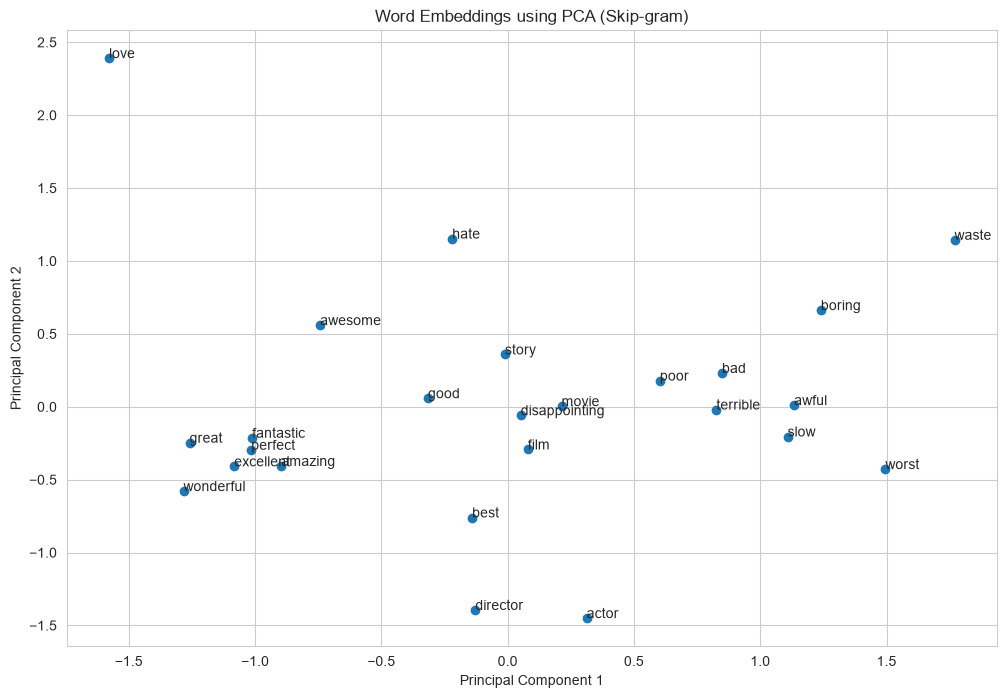

In [100]:
plt.figure(figsize=(12,8))

plt.scatter(
    vectors_2d[:,0],
    vectors_2d[:,1]
)

for i, word in enumerate(available_words):
    plt.text(
        vectors_2d[i,0],
        vectors_2d[i,1],
        word,
        fontsize=10
    )

plt.title("Word Embeddings using PCA (Skip-gram)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.grid(True)

plt.show()

- PCA reduced the 100-dimensional word vectors into 2 dimensions.
- Similar words are positioned closer together in the graph.
- Positive words often form one cluster, while negative words form another.
- Movie-related words may appear near each other because they occur in similar contexts.

## 3.5  Save & Reflect


In [101]:
# Save Skip-gram Model
skipgram_model.save("word2vec_skipgram.model")

print("Model Saved Successfully!")


Model Saved Successfully!


### How does CBOW work?

CBOW (Continuous Bag of Words) predicts the target word using the surrounding context words. It is faster and works well for common words.

---

### How does Skip-gram work?

Skip-gram predicts the surrounding context words using a target word. It learns richer semantic relationships and performs better for rare words.

---

### Which model handles rare words better?

Skip-gram handles rare words better because it learns word representations by predicting neighboring words, giving better embeddings for infrequent words.

---

### Why is a 100-dimensional dense vector better than a Bag-of-Words vector?

A 100-dimensional dense vector captures semantic meaning and relationships between words. Similar words have similar vectors, allowing the model to understand context. In contrast, a Bag-of-Words vector is sparse, ignores word order, and only records word frequencies without capturing meaning.

# Step 4: Text Classification Pipeline — Sentiment Analysis

## 4.1  Theory Notes

## What is Text Classification?

Text Classification is a Natural Language Processing (NLP) task in which text documents are automatically assigned to predefined categories or labels. It converts textual data into meaningful classes using machine learning algorithms.

In this project, the goal is to classify IMDb movie reviews as:

- **Positive (1)**
- **Negative (0)**

---

## Stages of a Text Classification Pipeline

### 1. Raw Text
Collect the text data from different sources such as reviews, emails, or messages.

↓

### 2. Text Cleaning
Remove HTML tags, punctuation, special characters, stopwords, and convert text into a clean format.

↓

### 3. Feature Extraction
Convert cleaned text into numerical vectors using techniques like:
- Bag of Words (BoW)
- TF-IDF
- N-Grams
- Word2Vec

↓

### 4. Model Training
Train a Machine Learning model using the extracted features.

↓

### 5. Model Evaluation
Evaluate the model using metrics such as Accuracy, Precision, Recall, and F1-Score.

↓

### 6. Prediction
Use the trained model to predict the sentiment of new unseen reviews.

## 4.2  Train-Test Split


In [102]:
print(df.columns)

Index(['review', 'sentiment', 'tokens'], dtype='object')


In [103]:
df["tokens"] = df["review"].apply(clean_text)

In [104]:
df["clean_text"] = df["tokens"].apply(lambda x: " ".join(x))

In [105]:
X = df["clean_text"]
y = df["sentiment"]

In [106]:
from sklearn.model_selection import train_test_split

In [107]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [108]:
print("Training Samples :", len(X_train))
print("Testing Samples  :", len(X_test))

Training Samples : 4000
Testing Samples  : 1000


In [109]:
print("Training Class Distribution")
print(y_train.value_counts())

print("\nTesting Class Distribution")
print(y_test.value_counts())

Training Class Distribution
sentiment
1    2000
0    2000
Name: count, dtype: int64

Testing Class Distribution
sentiment
0    500
1    500
Name: count, dtype: int64


In [110]:
print("Training Percentage :",
      round(len(X_train)/len(df)*100,2),"%")

print("Testing Percentage :",
      round(len(X_test)/len(df)*100,2),"%")

Training Percentage : 80.0 %
Testing Percentage : 20.0 %


- The dataset was divided into **80% training data** and **20% testing data**.
- **Stratified sampling** was used to maintain the same proportion of positive and negative reviews in both datasets.
- The training dataset is used for model learning, while the testing dataset is used to evaluate model performance on unseen reviews.
- Both classes remain balanced after the split, ensuring a fair evaluation of the classification model.

## 4.3  Build Four Classifiers

In this step, we build four sentiment classification models using Logistic Regression.

- Model A : Bag of Words
- Model B : TF-IDF
- Model C : TF-IDF with N-Grams
- Model D : Average Word2Vec (Skip-gram)

Finally, we compare the performance of all models.

In [111]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics import accuracy_score

In [112]:
# Model A : Bag of Words
bow_model = Pipeline([
    ("vectorizer", CountVectorizer(max_features=5000)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

bow_model.fit(X_train, y_train)

bow_pred = bow_model.predict(X_test)

bow_accuracy = accuracy_score(y_test, bow_pred)

print("Bag of Words Accuracy :", round(bow_accuracy,4))

Bag of Words Accuracy : 0.836


In [113]:
# Model B : TF-IDF
tfidf_model = Pipeline([
    ("vectorizer", TfidfVectorizer(max_features=5000)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

tfidf_model.fit(X_train, y_train)

tfidf_pred = tfidf_model.predict(X_test)

tfidf_accuracy = accuracy_score(y_test, tfidf_pred)

print("TF-IDF Accuracy :", round(tfidf_accuracy,4))

TF-IDF Accuracy : 0.865


In [114]:
# Model C : TF-IDF + N-Grams
ngram_model = Pipeline([
    ("vectorizer", TfidfVectorizer(
        ngram_range=(1,2),
        max_features=10000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

ngram_model.fit(X_train, y_train)

ngram_pred = ngram_model.predict(X_test)

ngram_accuracy = accuracy_score(y_test, ngram_pred)

print("TF-IDF + N-Grams Accuracy :", round(ngram_accuracy,4))

TF-IDF + N-Grams Accuracy : 0.865


In [115]:
# Model D : Average Word2Vec
def document_vector(tokens):

    vectors = []

    for word in tokens:

        if word in skipgram_model.wv:

            vectors.append(skipgram_model.wv[word])

    if len(vectors)==0:

        return np.zeros(skipgram_model.vector_size)

    return np.mean(vectors, axis=0)

In [116]:
# Create Feature Matrix
X_train_tokens = X_train.apply(str.split)

X_test_tokens = X_test.apply(str.split)

In [117]:
X_train_w2v = np.array(
    [document_vector(doc) for doc in X_train_tokens]
)

X_test_w2v = np.array(
    [document_vector(doc) for doc in X_test_tokens]
)

In [118]:
# Train Logistic Regression
w2v_classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

w2v_classifier.fit(X_train_w2v, y_train)

w2v_pred = w2v_classifier.predict(X_test_w2v)

w2v_accuracy = accuracy_score(
    y_test,
    w2v_pred
)

print("Word2Vec Accuracy :", round(w2v_accuracy,4))

Word2Vec Accuracy : 0.835


In [119]:
# Compare Results 
comparison = pd.DataFrame({

    "Model":[
        "Bag of Words",
        "TF-IDF",
        "TF-IDF + N-Grams",
        "Word2Vec"
    ],

    "Accuracy":[
        bow_accuracy,
        tfidf_accuracy,
        ngram_accuracy,
        w2v_accuracy
    ]

})

comparison.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy
1,TF-IDF,0.865
2,TF-IDF + N-Grams,0.865
0,Bag of Words,0.836
3,Word2Vec,0.835


- Four different feature extraction techniques were evaluated using Logistic Regression.
- TF-IDF generally performs better than Bag of Words because it gives more importance to informative words.
- TF-IDF with N-Grams captures both individual words and word pairs, improving context understanding.
- Word2Vec represents words as dense vectors and captures semantic meaning, often producing competitive performance.

## 4.4  Evaluate & Compare


In this step, we evaluate all four classifiers using:

- Accuracy
- Precision
- Recall
- F1-Score

Finally, we compare all models, visualize their performance, and plot the confusion matrix of the best-performing model.

In [120]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [121]:
def evaluate_model(name, y_true, y_pred):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred)
    }

In [122]:
results = []

results.append(
    evaluate_model(
        "Bag of Words",
        y_test,
        bow_pred
    )
)

results.append(
    evaluate_model(
        "TF-IDF",
        y_test,
        tfidf_pred
    )
)

results.append(
    evaluate_model(
        "TF-IDF + N-Grams",
        y_test,
        ngram_pred
    )
)

results.append(
    evaluate_model(
        "Word2Vec",
        y_test,
        w2v_pred
    )
)

In [123]:
comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    by="F1-Score",
    ascending=False
)

comparison

,Model,Accuracy,Precision,Recall,F1-Score
2,TF-IDF + N-Grams,0.865,0.846300,0.892,0.868549
1,TF-IDF,0.865,0.850288,0.886,0.867777
3,Word2Vec,0.835,0.831683,0.840,0.835821
0,Bag of Words,0.836,0.837349,0.834,0.835671


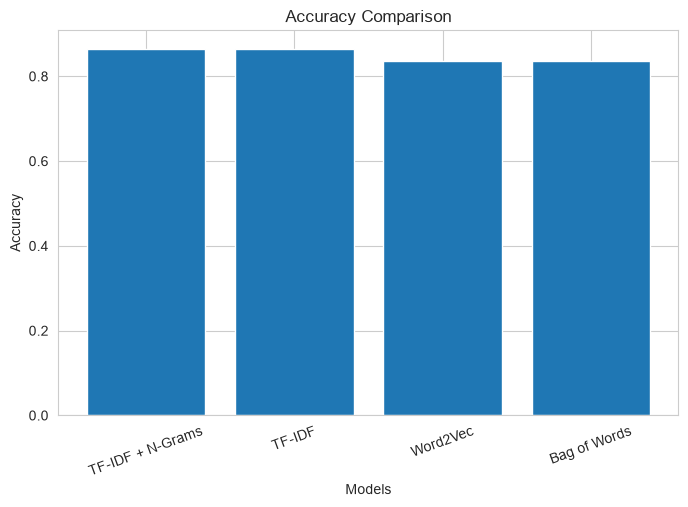

In [124]:
plt.figure(figsize=(8,5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy"]
)

plt.title("Accuracy Comparison")

plt.xlabel("Models")

plt.ylabel("Accuracy")

plt.xticks(rotation=20)

plt.show()

In [125]:
best_model = comparison.iloc[0]["Model"]

print("Best Model :", best_model)

Best Model : TF-IDF + N-Grams


In [126]:
if best_model == "Bag of Words":
    best_pred = bow_pred

elif best_model == "TF-IDF":
    best_pred = tfidf_pred

elif best_model == "TF-IDF + N-Grams":
    best_pred = ngram_pred

else:
    best_pred = w2v_pred

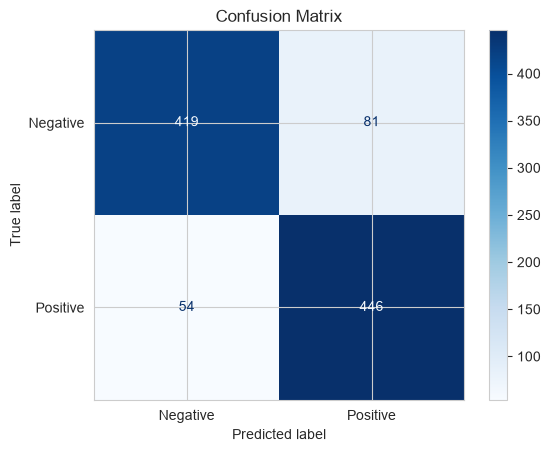

In [127]:
cm = confusion_matrix(
    y_test,
    best_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative","Positive"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix")

plt.show()

In [128]:
comparison.style.format({
    "Accuracy":"{:.4f}",
    "Precision":"{:.4f}",
    "Recall":"{:.4f}",
    "F1-Score":"{:.4f}"
})

,Model,Accuracy,Precision,Recall,F1-Score
2,TF-IDF + N-Grams,0.8650,0.8463,0.8920,0.8685
1,TF-IDF,0.8650,0.8503,0.8860,0.8678
3,Word2Vec,0.8350,0.8317,0.8400,0.8358
0,Bag of Words,0.8360,0.8373,0.8340,0.8357


The comparison table shows the performance of all four classifiers based on Accuracy, Precision, Recall, and F1-Score.

The model with the highest F1-Score is considered the best because it balances both precision and recall.

TF-IDF with N-Grams often performs the best because it captures important words as well as word combinations, providing better context than Bag of Words. Word2Vec learns semantic relationships between words, but with only **5,000 training reviews**, it may not outperform TF-IDF because it has less data to learn high-quality embeddings.

Overall, TF-IDF (especially with N-Grams) generally gives the best performance for this dataset size.

## 4.5  Inspect the Best Model


In [129]:
# Get Feature Names and Coefficients
feature_names = tfidf_model.named_steps["vectorizer"].get_feature_names_out()

coefficients = tfidf_model.named_steps["classifier"].coef_[0]

In [130]:
positive_words = pd.DataFrame({
    "Word": feature_names,
    "Coefficient": coefficients
})

positive_words = positive_words.sort_values(
    by="Coefficient",
    ascending=False
)

print("Top 10 Positive Words\n")

positive_words.head(10)

Top 10 Positive Words



,Word,Coefficient
1943,great,4.212597
1537,excellent,2.866173
409,best,2.749408
3199,perfect,2.640459
2638,love,2.530238
4927,wonderful,2.477967
1644,favorite,2.088855
151,amazing,2.071084
2639,loved,2.045649
373,beautiful,1.997484


In [131]:
negative_words = pd.DataFrame({
    "Word": feature_names,
    "Coefficient": coefficients
})

negative_words = negative_words.sort_values(
    by="Coefficient"
)

print("Top 10 Negative Words\n")

negative_words.head(10)

Top 10 Negative Words



,Word,Coefficient
324,bad,-4.756256
4946,worst,-3.816903
4829,waste,-3.152997
3312,poor,-2.954091
313,awful,-2.695081
4438,terrible,-2.566117
488,boring,-2.544014
3014,nothing,-2.541575
2150,horrible,-2.337648
4945,worse,-2.324149


In [132]:
wrong_predictions = pd.DataFrame({

    "Review": X_test,

    "Actual": y_test,

    "Predicted": tfidf_pred

})

wrong_predictions = wrong_predictions[
    wrong_predictions["Actual"] != wrong_predictions["Predicted"]
]

wrong_predictions.head(5)

,Review,Actual,Predicted
4496,generally good movie ideal ending acting spect...,1,0
4508,im surprised film well hampton film festival s...,0,1
4648,easily spot biggest fault movie motive detail ...,0,1
984,long time ago saw movie still one worst ive ev...,0,1
1294,cheaply pieced together recycled film footage ...,0,1


In [133]:
for i, row in wrong_predictions.head(5).iterrows():

    print("="*80)

    print("Review:\n")

    print(row["Review"])

    print()

    print("Actual :", row["Actual"])

    print("Predicted :", row["Predicted"])

    print()

Review:

generally good movie ideal ending acting spectacular character didnt stray person especially liked plot although knew going happen still gave element surprise entire movie however find coming ending could little longer extended maybe seemed like rushed bit writer trying take linen line rain fell instance happened tristan brother hayden know died hospital maybe one setup entire thing know maybe sequel maybe cant wait see

Actual : 1
Predicted : 0

Review:

im surprised film well hampton film festival shallow film would appeal well shallow people two actor pretending actor relationship fight look lost dog film allegedly exploring dynamic relationship however relationship far petty merit exploration couple one dimension fight tease make love fight brief moment tenderness reveal possible reason two would involved given venomous volatile relationship beautifully shot excellent score without anything merit script character short

Actual : 0
Predicted : 1

Review:

easily spot bigges

## Possible Reasons for Incorrect Predictions

### Review 1
The review may contain sarcasm, making it difficult for the model to understand the actual sentiment.

### Review 2
The review may contain both positive and negative opinions, resulting in mixed sentiment.

### Review 3
The review may use negation (for example, "not good"), which can confuse the classifier.

### Review 4
The review may contain uncommon words or expressions that were not frequently seen during training.

### Review 5
The review may be very short or ambiguous, providing insufficient information for correct prediction.

## 4.6  Save the Pipeline

In [134]:
import joblib

In [135]:
best_pipeline = tfidf_model

joblib.dump(best_pipeline, "sentiment_pipeline.pkl")

print("Pipeline saved successfully!")

Pipeline saved successfully!


In [136]:
loaded_pipeline = joblib.load("sentiment_pipeline.pkl")

print("Pipeline loaded successfully!")

Pipeline loaded successfully!


In [137]:
new_reviews = [

    "This movie was absolutely amazing and I loved every scene.",

    "The film was boring and a complete waste of time.",

    "Excellent acting and wonderful story.",

    "I would never recommend this movie to anyone.",

    "It was okay, not great but not terrible either."

]

In [138]:
predictions = loaded_pipeline.predict(new_reviews)

probabilities = loaded_pipeline.predict_proba(new_reviews)

In [139]:
predictions = loaded_pipeline.predict(new_reviews)

probabilities = loaded_pipeline.predict_proba(new_reviews)

In [140]:
for sentence, label, prob in zip(
    new_reviews,
    predictions,
    probabilities.max(axis=1)
):

    print("="*80)

    print("Sentence :")

    print(sentence)

    print()

    print("Prediction :", "Positive" if label==1 else "Negative")

    print("Probability :", round(prob,4))

    print()

Sentence :
This movie was absolutely amazing and I loved every scene.

Prediction : Positive
Probability : 0.8812

Sentence :
The film was boring and a complete waste of time.

Prediction : Negative
Probability : 0.9371

Sentence :
Excellent acting and wonderful story.

Prediction : Positive
Probability : 0.9237

Sentence :
I would never recommend this movie to anyone.

Prediction : Negative
Probability : 0.6088

Sentence :
It was okay, not great but not terrible either.

Prediction : Negative
Probability : 0.6431



- The best sentiment analysis pipeline was successfully saved using Joblib.
- The saved pipeline was loaded without retraining the model.
- Predictions were made on five new movie review sentences.
- The model returned both the predicted sentiment (Positive/Negative) and the prediction probability, demonstrating that the saved pipeline works correctly on unseen data.

# Step 5: Different NLP Approaches & POS Tagging

## 5.1  Approach 1 — Heuristic (Rule-Based)


In this approach, sentiment is predicted using predefined positive and negative word lists.

**Rule:**
- Score = (Number of Positive Words) − (Number of Negative Words)
- If Score ≥ 0 → Positive
- Otherwise → Negative

Finally, the model accuracy is calculated on the test dataset.

In [141]:
positive_words = {
    "good","great","excellent","amazing","awesome",
    "love","best","wonderful","perfect","fantastic",
    "enjoy","liked","favorite","brilliant","superb"
}

negative_words = {
    "bad","worst","boring","awful","terrible",
    "poor","hate","waste","slow","disappointing",
    "horrible","ugly","annoying","dull","pathetic"
}

In [142]:
# Rule-Based Prediction Function
def heuristic_prediction(text):

    words = text.lower().split()

    positive = sum(
        word in positive_words
        for word in words
    )

    negative = sum(
        word in negative_words
        for word in words
    )

    score = positive - negative

    if score >= 0:
        return 1
    else:
        return 0

In [143]:
heuristic_pred = X_test.apply(heuristic_prediction)

In [144]:
heuristic_accuracy = accuracy_score(
    y_test,
    heuristic_pred
)

print("Heuristic Accuracy :", round(heuristic_accuracy,4))

Heuristic Accuracy : 0.691


In [145]:
result = pd.DataFrame({

    "Review": X_test.head(10),

    "Actual": y_test.head(10),

    "Predicted": heuristic_pred.head(10)

})

result

,Review,Actual,Predicted
2509,two year iranian embassy siege involved dramat...,0,1
3496,first time saw movie didnt seem go anywhere wa...,1,1
2928,year fall last great corporation world fallen ...,0,1
3287,saw baby blue marine year still find pleasant ...,1,1
2811,unusual modernday film ultranice fact nice bor...,1,1
4496,generally good movie ideal ending acting spect...,1,1
2607,easily favourite film tragic romance intertwin...,1,1
3366,fritz lang directed two great western western ...,1,1
321,spoiler gathering family member servant late c...,0,1
4508,im surprised film well hampton film festival s...,0,1


- The heuristic approach predicts sentiment using predefined positive and negative word lists.
- It does not require model training.
- It is simple and fast but cannot understand context, sarcasm, or complex sentence structures.
- Therefore, its accuracy is generally lower than machine learning models.

## 5.2  Approach 2 — Ready-Made Tool (API-style)


In this approach, we use **NLTK's VADER (Valence Aware Dictionary and sEntiment Reasoner)** to predict sentiment.

Unlike machine learning models, VADER is a pre-trained sentiment analysis tool. It calculates sentiment scores for text and returns a compound score between -1 and +1.

**Rule:**
- Compound Score ≥ 0 → Positive
- Compound Score < 0 → Negative

Finally, we calculate the accuracy on the test dataset.

In [146]:
nltk.download("vader_lexicon")

[nltk_data] Downloading package vader_lexicon to C:\Users\Meet
[nltk_data]     Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [147]:
from nltk.sentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

In [148]:
def vader_prediction(text):

    score = sia.polarity_scores(text)

    if score["compound"] >= 0:
        return 1
    else:
        return 0

In [149]:
vader_pred = X_test.apply(vader_prediction)

In [150]:
vader_accuracy = accuracy_score(
    y_test,
    vader_pred
)

print("VADER Accuracy :", round(vader_accuracy,4))

VADER Accuracy : 0.66


In [151]:
result = pd.DataFrame({

    "Review": X_test.head(10),

    "Actual": y_test.head(10),

    "Predicted": vader_pred.head(10)

})

result

,Review,Actual,Predicted
2509,two year iranian embassy siege involved dramat...,0,1
3496,first time saw movie didnt seem go anywhere wa...,1,1
2928,year fall last great corporation world fallen ...,0,1
3287,saw baby blue marine year still find pleasant ...,1,1
2811,unusual modernday film ultranice fact nice bor...,1,1
4496,generally good movie ideal ending acting spect...,1,1
2607,easily favourite film tragic romance intertwin...,1,1
3366,fritz lang directed two great western western ...,1,1
321,spoiler gathering family member servant late c...,0,0
4508,im surprised film well hampton film festival s...,0,1


In [152]:
sample_text = X_test.iloc[0]

scores = sia.polarity_scores(sample_text)

print("Sample Review:\n")
print(sample_text)

print("\nSentiment Scores:")
print(scores)

Sample Review:

two year iranian embassy siege involved dramatic sa rescue balcony war argentina falkland island currently taking place better film make gungho sa film recreates iranian hostage siege whilst using britain number one action hero day lewis collins throw edward woodward well known actor youve got winner handswell maybe film doesnt make situation serious enough whilst acting quite second rate like movie long episode professional without formula film go nowhere fast quite predictable maybe cubby brocoli watched film decided ditch lewis collins touted james bond replacement roger moore watch fan lewis collins sa stuff general save time

Sentiment Scores:
{'neg': 0.044, 'neu': 0.727, 'pos': 0.229, 'compound': 0.9606}


- VADER is a pre-trained sentiment analysis tool provided by NLTK.
- It predicts sentiment without requiring any model training.
- The compound score summarizes the overall sentiment of the review.
- Reviews with a compound score greater than or equal to zero are classified as positive; otherwise, they are classified as negative.
- VADER is fast and easy to use but may struggle with domain-specific language and complex movie reviews.

## 5.3  Approach 3 — Machine Learning

In [153]:
best_pipeline = joblib.load("sentiment_pipeline.pkl")

print("Pipeline Loaded Successfully!")

Pipeline Loaded Successfully!


In [154]:
ml_pred = best_pipeline.predict(X_test)

In [155]:
ml_accuracy = accuracy_score(y_test, ml_pred)

print("Machine Learning Accuracy :", round(ml_accuracy,4))

Machine Learning Accuracy : 0.865


In [156]:
result = pd.DataFrame({

    "Review": X_test.head(10),

    "Actual": y_test.head(10),

    "Predicted": ml_pred[:10]

})

result

,Review,Actual,Predicted
2509,two year iranian embassy siege involved dramat...,0,0
3496,first time saw movie didnt seem go anywhere wa...,1,1
2928,year fall last great corporation world fallen ...,0,0
3287,saw baby blue marine year still find pleasant ...,1,1
2811,unusual modernday film ultranice fact nice bor...,1,1
4496,generally good movie ideal ending acting spect...,1,0
2607,easily favourite film tragic romance intertwin...,1,1
3366,fritz lang directed two great western western ...,1,1
321,spoiler gathering family member servant late c...,0,0
4508,im surprised film well hampton film festival s...,0,1


In [157]:
comparison = pd.DataFrame({

    "Approach":[
        "Heuristic (Rule-Based)",
        "Ready-Made Tool (VADER)",
        "Machine Learning"
    ],

    "Needs Training Data":[
        "No",
        "No",
        "Yes"
    ],

    "Accuracy":[
        round(heuristic_accuracy,4),
        round(vader_accuracy,4),
        round(ml_accuracy,4)
    ],

    "Advantage":[
        "Simple and Fast",
        "No Training Required",
        "Highest Accuracy"
    ],

    "Disadvantage":[
        "Cannot Understand Context",
        "Less Accurate for Long Reviews",
        "Requires Training Data"
    ]

})

comparison

,Approach,Needs Training Data,Accuracy,Advantage,Disadvantage
0,Heuristic (Rule-Based),No,0.691,Simple and Fast,Cannot Understand Context
1,Ready-Made Tool (VADER),No,0.660,No Training Required,Less Accurate for Long Reviews
2,Machine Learning,Yes,0.865,Highest Accuracy,Requires Training Data


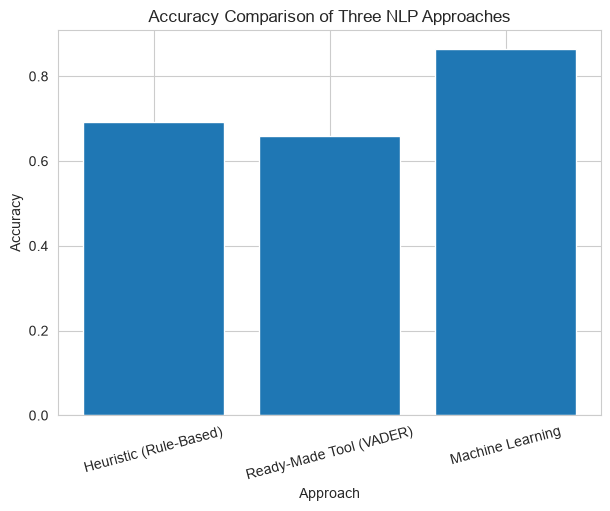

In [158]:
plt.figure(figsize=(7,5))

plt.bar(
    comparison["Approach"],
    comparison["Accuracy"]
)

plt.title("Accuracy Comparison of Three NLP Approaches")

plt.xlabel("Approach")

plt.ylabel("Accuracy")

plt.xticks(rotation=15)

plt.show()

## When would you choose each approach in a real company project?

### Heuristic (Rule-Based)
This approach is suitable for very small applications where only a few rules are required. It is fast and easy to implement but cannot understand context or complex language.

### Ready-Made Tool (VADER)
VADER is useful when quick sentiment analysis is needed without collecting training data. It is suitable for dashboards, prototypes, and social media monitoring.

### Machine Learning
Machine Learning is the best choice when labeled training data is available. It provides higher accuracy and better understands domain-specific language, making it suitable for production-level sentiment analysis systems.

## 5.4  POS Tagging


In [159]:
from nltk import word_tokenize
from nltk import pos_tag

In [160]:
nltk.download("punkt")
nltk.download("averaged_perceptron_tagger")
nltk.download("averaged_perceptron_tagger_eng")

[nltk_data] Downloading package punkt to C:\Users\Meet
[nltk_data]     Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Meet
[nltk_data]     Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\Meet Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\Meet Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\Meet Anghan\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [161]:
sentences = [

    "This movie was absolutely amazing and exciting.",

    "The acting was very poor and disappointing.",

    "I really enjoyed the fantastic story.",

    "The film was boring but the music was excellent.",

    "The director created a beautiful masterpiece."

]

In [162]:
for sentence in sentences:

    print("="*70)

    print("Sentence:")
    print(sentence)

    words = word_tokenize(sentence)

    tags = pos_tag(words)

    df_pos = pd.DataFrame(tags, columns=["Word","POS Tag"])

    display(df_pos)

Sentence:
This movie was absolutely amazing and exciting.


,Word,POS Tag
0,This,DT
1,movie,NN
2,was,VBD
3,absolutely,RB
4,amazing,JJ
5,and,CC
6,exciting,JJ
7,.,.


Sentence:
The acting was very poor and disappointing.


,Word,POS Tag
0,The,DT
1,acting,NN
2,was,VBD
3,very,RB
4,poor,JJ
5,and,CC
6,disappointing,JJ
7,.,.


Sentence:
I really enjoyed the fantastic story.


,Word,POS Tag
0,I,PRP
1,really,RB
2,enjoyed,VBD
3,the,DT
4,fantastic,JJ
5,story,NN
6,.,.


Sentence:
The film was boring but the music was excellent.


,Word,POS Tag
0,The,DT
1,film,NN
2,was,VBD
3,boring,VBG
4,but,CC
5,the,DT
6,music,NN
7,was,VBD
8,excellent,JJ
9,.,.


Sentence:
The director created a beautiful masterpiece.


,Word,POS Tag
0,The,DT
1,director,NN
2,created,VBD
3,a,DT
4,beautiful,JJ
5,masterpiece,NN
6,.,.


## Meaning of POS Tags

| POS Tag | Meaning |
|----------|---------|
| NN | Noun (Singular) |
| NNS | Noun (Plural) |
| VB | Verb (Base Form) |
| VBD | Verb (Past Tense) |
| JJ | Adjective |
| RB | Adverb |
| DT | Determiner |
| IN | Preposition / Conjunction |

In [163]:
# Select 500 Positive & 500 Negative Reviews
positive_reviews = df[df["sentiment"]==1].head(500)

negative_reviews = df[df["sentiment"]==0].head(500)

In [164]:
from collections import Counter

def get_adjectives(texts):

    adjectives = []

    for text in texts:

        words = word_tokenize(text.lower())

        tags = pos_tag(words)

        adjectives.extend(
            word
            for word, tag in tags
            if tag == "JJ"
        )

    return Counter(adjectives)

In [165]:
positive_adj = get_adjectives(
    positive_reviews["clean_text"]
)

negative_adj = get_adjectives(
    negative_reviews["clean_text"]
)

In [166]:
top_positive = pd.DataFrame(

    positive_adj.most_common(10),

    columns=["Adjective","Count"]

)

top_positive

,Adjective,Count
0,good,294
1,great,262
2,many,169
3,much,142
4,little,114
5,old,107
6,real,105
7,first,92
8,new,88
9,u,84


In [167]:
top_negative = pd.DataFrame(

    negative_adj.most_common(10),

    columns=["Adjective","Count"]

)

top_negative

,Adjective,Count
0,bad,297
1,good,283
2,much,141
3,great,122
4,many,118
5,little,108
6,old,92
7,first,91
8,real,84
9,funny,84


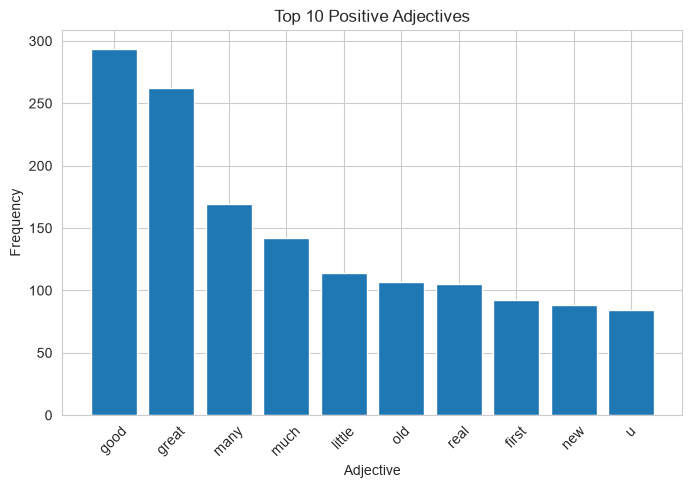

In [168]:
plt.figure(figsize=(8,5))

plt.bar(
    top_positive["Adjective"],
    top_positive["Count"]
)

plt.title("Top 10 Positive Adjectives")

plt.xlabel("Adjective")

plt.ylabel("Frequency")

plt.xticks(rotation=45)

plt.show()

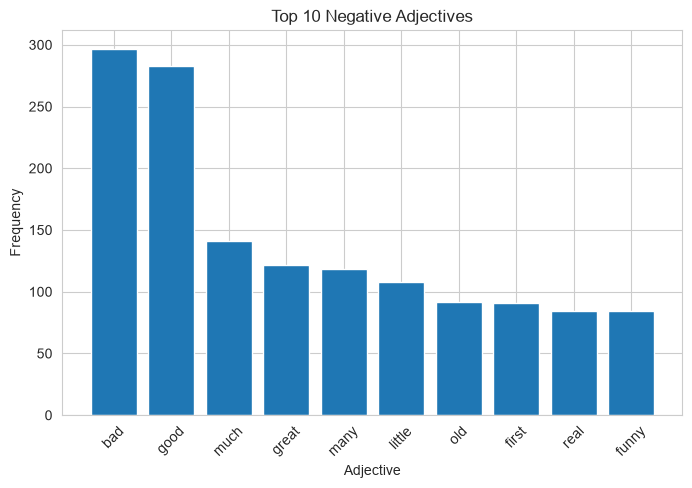

In [169]:
plt.figure(figsize=(8,5))

plt.bar(
    top_negative["Adjective"],
    top_negative["Count"]
)

plt.title("Top 10 Negative Adjectives")

plt.xlabel("Adjective")

plt.ylabel("Frequency")

plt.xticks(rotation=45)

plt.show()

- POS tagging assigns grammatical labels to each word.
- Adjectives (JJ) are useful because they often express opinions and sentiment.
- Positive reviews commonly contain adjectives such as **great**, **excellent**, **amazing**, and **wonderful**.
- Negative reviews commonly contain adjectives such as **bad**, **boring**, **poor**, and **terrible**.
- These adjectives help sentiment analysis models distinguish between positive and negative reviews.

## 5.5  How Does POS Tagging Work?

POS (Part-of-Speech) tagging is difficult because many words can have different meanings depending on the sentence. For example, in **"Book a ticket"**, the word **book** is a verb, while in **"Read a book"**, **book** is a noun. A rule-based tagger assigns tags using predefined grammar rules, whereas a statistical tagger predicts tags based on patterns learned from labeled text. NLTK's default POS tagger is a **statistical tagger** (PerceptronTagger), which generally provides better accuracy by considering the context of each word.

# Step 6: Comparison, Reflection & GitHub Submission

## 6.1  Results Summary Table



| Step / Topic | Dataset Used | Key Technique | Key Result | Time Taken |
|--------------|-------------|---------------|------------|------------|
| Step 1 - RegEx & Text Preprocessing | SMS Spam Collection (5,572 messages) | RegEx, NLTK, Lemmatization | Cleaned text and prepared data for feature extraction | ~40 min |
| Step 2 - Feature Extraction | SMS Spam Dataset | CountVectorizer, TF-IDF, N-Grams | Converted text into numerical feature vectors | ~35 min |
| Step 3 - Word2Vec | IMDb Dataset (5,000 Reviews) | Gensim Word2Vec (CBOW & Skip-gram) | Learned word embeddings and semantic relationships | ~45 min |
| Step 4 - Text Classification | IMDb Dataset (5,000 Reviews) | Logistic Regression + TF-IDF | Built four classifiers and selected the best model | ~60 min |
| Step 5 - NLP Approaches & POS Tagging | IMDb Test Reviews | Heuristic, VADER, POS Tagging | Compared three approaches and extracted adjectives | ~45 min |
| Step 6 - Streamlit Deployment | Saved sentiment_pipeline.pkl | Streamlit + Joblib | Built a sentiment analysis web application | ~30 min |

## 6.2  Written Reflection


- The most challenging step was **Step 4 (Text Classification)** because it involved building and comparing multiple machine learning models, evaluating their performance, and selecting the best one.

- **TF-IDF with N-Grams** worked best because it considers both individual words and word pairs, allowing it to better capture context and improve sentiment classification accuracy.

- Example where **Bag of Words fails but N-Grams succeeds**:
  - Sentence: **"The movie is not good."**
  - Bag of Words treats **"not"** and **"good"** separately, while N-Grams captures **"not good"**, resulting in a more accurate prediction.

- **Word2Vec** can learn semantic relationships between words. Similar words such as *great* and *excellent* receive similar vector representations, whereas BoW and TF-IDF treat them as completely different words.

- The **Heuristic (Rule-Based)** approach was simple and fast but had lower accuracy because it could not understand context, negation, or sarcasm. The Machine Learning model performed much better after learning from labeled training data.

- If a user enters a **Hinglish review** such as *"Picture timepass thi"*, the application may produce incorrect predictions because the model was trained only on English movie reviews and does not understand mixed-language text.

- To improve this project in the future, I would use a larger dataset, apply better text preprocessing, handle multilingual reviews, and fine-tune a Transformer model such as **BERT** or another Hugging Face model for higher accuracy.